In [3]:
import pandas as pd
from pathlib import Path

PROCESSED = Path("../data/processed")
REPORTS = Path("../reports")
REPORTS.mkdir(exist_ok=True)

mart = pd.read_parquet(
    PROCESSED / "mart_manufacturer_drug_month.parquet"
)

mart["event_month"] = pd.to_datetime(mart["event_month"])
mart = mart.sort_values(["manufacturer", "drug_name", "event_month"])

mart.shape

(1362400, 21)

In [4]:
mart.columns

Index(['manufacturer', 'drug_name', 'event_month', 'events_count',
       'batches_count', 'letters_count', 'regions_affected',
       'first_event_date', 'last_event_date', 'events_lag_1m', 'events_lag_3m',
       'events_lag_6m', 'events_rolling_3m', 'events_rolling_6m',
       'events_rolling_12m', 'events_rolling_3m_mean',
       'events_rolling_12m_mean', 'risk_flag_spike', 'risk_flag_repeated',
       'risk_flag_active_month', 'risk_score_v0'],
      dtype='object')

In [5]:
last_month = mart["event_month"].max()
last_month

Timestamp('2026-10-01 00:00:00')

In [6]:
last_month_data = mart[mart["event_month"] == last_month]

top_manufacturers = (
    last_month_data
    .groupby("manufacturer", as_index=False)
    .agg(
        events_count=("events_count", "sum"),
        drugs_count=("drug_name", "nunique"),
        batches_count=("batches_count", "sum"),
    )
    .sort_values("events_count", ascending=False)
    .head(20)
)

top_manufacturers

,manufacturer,events_count,drugs_count,batches_count
1363,"публичное акционерное общество ""акционерное ку...",2.0,4,2.0
104,"акционерное общество ""химико-фармацевтический ...",1.0,7,1.0
1082,"общество с ограниченной ответственностью ""велф...",1.0,1,1.0
1120,"общество с ограниченной ответственностью ""прои...",1.0,2,1.0
1268,"открытое акционерное общество ""акционерное кур...",0.0,20,0.0
1264,орхид хелскэр (подразделение орхид кемикалз эн...,0.0,3,0.0
1265,"открыте акционерное общество ""ереванская химик...",0.0,1,0.0
1266,"открытое акционерное обшество ""усолье-сибирски...",0.0,1,0.0
1267,"открытое акционерное общество ""акционерное кур...",0.0,4,0.0
0,,0.0,17,0.0


In [7]:
top_drugs = (
    last_month_data
    .groupby(["manufacturer", "drug_name"], as_index=False)
    .agg(
        events_count=("events_count", "sum"),
        batches_count=("batches_count", "sum"),
        letters_count=("letters_count", "sum"),
    )
    .sort_values("events_count", ascending=False)
    .head(20)
)

top_drugs

,manufacturer,drug_name,events_count,batches_count,letters_count
3037,"общество с ограниченной ответственностью ""прои...",симетикон,1.0,1.0,1.0
3685,"публичное акционерное общество ""акционерное ку...",кеторолак,1.0,1.0,1.0
2900,"общество с ограниченной ответственностью ""велф...",ибупрофен велфарм,1.0,1.0,1.0
298,"акционерное общество ""химико-фармацевтический ...",капотен,1.0,1.0,1.0
3684,"публичное акционерное общество ""акционерное ку...",бронхорус,1.0,1.0,1.0
3470,"открытое акционерное общество ""ирбитский химик...",ранитидин,0.0,0.0,0.0
3469,"открытое акционерное общество ""ирбитский химик...",калия оротат,0.0,0.0,0.0
3468,"открытое акционерное общество ""ирбитский химик...",валидол с изомальтом,0.0,0.0,0.0
3467,"открытое акционерное общество ""ирбитский химик...",бисопролол авексима,0.0,0.0,0.0
3466,"открытое акционерное общество ""ирбитский химик...",уголь активированный,0.0,0.0,0.0


In [8]:
monthly = (
    mart
    .groupby("event_month", as_index=False)
    .agg(
        events_count=("events_count", "sum"),
        manufacturers_count=("manufacturer", "nunique"),
        drugs_count=("drug_name", "nunique"),
    )
    .sort_values("event_month")
)

monthly.tail(24)

,event_month,events_count,manufacturers_count,drugs_count
238,2024-11-01,60.0,1900,2641
239,2024-12-01,59.0,1900,2641
240,2025-01-01,15.0,1900,2641
241,2025-02-01,35.0,1900,2641
242,2025-03-01,187.0,1900,2641
243,2025-04-01,62.0,1900,2641
244,2025-05-01,84.0,1900,2641
245,2025-06-01,27.0,1900,2641
246,2025-07-01,223.0,1900,2641
247,2025-08-01,33.0,1900,2641


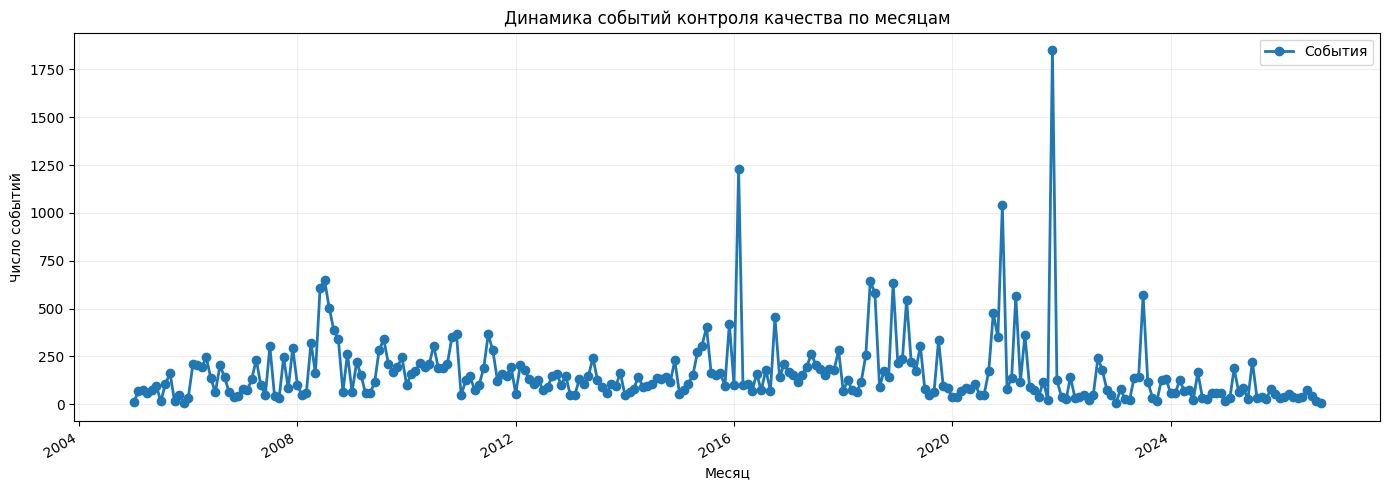

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    monthly["event_month"],
    monthly["events_count"],
    marker="o",
    linewidth=2,
    label="События",
)

ax.set_title("Динамика событий контроля качества по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Число событий")
ax.grid(alpha=0.2)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [10]:
mart["events_prev_month"] = (
    mart.groupby(["manufacturer", "drug_name"])["events_count"]
    .shift(1)
)

mart["events_change"] = (
    mart["events_count"] - mart["events_prev_month"]
)

In [11]:
top_growth = (
    mart[mart["event_month"] == last_month]
    .sort_values("events_change", ascending=False)
    .head(20)
)

top_growth[
    [
        "manufacturer",
        "drug_name",
        "event_month",
        "events_prev_month",
        "events_count",
        "events_change",
    ]
]

,manufacturer,drug_name,event_month,events_prev_month,events_count,events_change
965469,"публичное акционерное общество ""акционерное ку...",бронхорус,2026-10-01,0.0,1.0,1.0
78337,"акционерное общество ""химико-фармацевтический ...",капотен,2026-10-01,0.0,1.0,1.0
965731,"публичное акционерное общество ""акционерное ку...",кеторолак,2026-10-01,0.0,1.0,1.0
261,,аримидекс,2026-10-01,0.0,0.0,0.0
910187,"открытое акционерное общество ""ирбитский химик...",циннаризин,2026-10-01,0.0,0.0,0.0
909663,"открытое акционерное общество ""ирбитский химик...",сановаск,2026-10-01,0.0,0.0,0.0
909401,"открытое акционерное общество ""ирбитский химик...",ранитидин,2026-10-01,0.0,0.0,0.0
909139,"открытое акционерное общество ""ирбитский химик...",калия оротат,2026-10-01,0.0,0.0,0.0
908877,"открытое акционерное общество ""ирбитский химик...",валидол с изомальтом,2026-10-01,0.0,0.0,0.0
908615,"открытое акционерное общество ""ирбитский химик...",бисопролол авексима,2026-10-01,0.0,0.0,0.0


In [12]:
mart["is_spike"] = (
    (mart["events_count"] >= 3)
    & (mart["events_count"] >= 2 * mart["events_prev_month"])
).astype(int)

In [13]:
spikes = (
    mart[mart["event_month"] == last_month]
    .sort_values(
        ["events_count", "events_change"],
        ascending=[False, False],
    )
    .head(20)
)

spikes[
    [
        "manufacturer",
        "drug_name",
        "event_month",
        "events_prev_month",
        "events_count",
        "events_change",
        "is_spike",
    ]
]

,manufacturer,drug_name,event_month,events_prev_month,events_count,events_change,is_spike
78337,"акционерное общество ""химико-фармацевтический ...",капотен,2026-10-01,0.0,1.0,1.0,0
965469,"публичное акционерное общество ""акционерное ку...",бронхорус,2026-10-01,0.0,1.0,1.0,0
965731,"публичное акционерное общество ""акционерное ку...",кеторолак,2026-10-01,0.0,1.0,1.0,0
795955,"общество с ограниченной ответственностью ""прои...",симетикон,2026-10-01,1.0,1.0,0.0,0
760061,"общество с ограниченной ответственностью ""велф...",ибупрофен велфарм,2026-10-01,2.0,1.0,-1.0,0
261,,аримидекс,2026-10-01,0.0,0.0,0.0,0
523,,бификол сухой,2026-10-01,0.0,0.0,0.0,0
785,,бонвива,2026-10-01,0.0,0.0,0.0,0
1047,,боярышника плоды,2026-10-01,0.0,0.0,0.0,0
1309,,калия йодид,2026-10-01,0.0,0.0,0.0,0


In [14]:
mart.to_parquet(
    PROCESSED / "mart_manufacturer_drug_month_monitoring.parquet",
    index=False,
)